11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9224 - loss: 0.2665 - val_accuracy: 0.9572 - val_loss: 0.1442
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9666 - loss: 0.1122 - val_accuracy: 0.9651 - val_loss: 0.1139
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9756 - loss: 0.0780 - val_accuracy: 0.9722 - val_loss: 0.1022
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9805 - loss: 0.0602 - val_accuracy: 0.9720 - val_loss: 0.0952
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9862 - loss: 0.0439 - val_accuracy: 0.9720 - val_loss: 0.0974
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9881 - loss: 0.0382 - val_accuracy: 0.9740 - val_loss: 0.0940
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9901 - loss: 0.0311 - val_accuracy: 0.9745 - val_loss: 0.0973
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9919 - loss: 0.0250 -

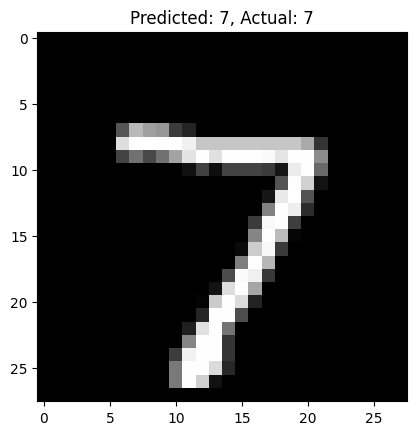

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt

# Load and preprocess MNIST dataset
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

X_train, X_test = X_train / 255.0, X_test / 255.0   # Normalize data

X_train = X_train.reshape(-1, 28 * 28)   # Flatten images
X_test = X_test.reshape(-1, 28 * 28)

y_train = keras.utils.to_categorical(y_train, 10)   # One-hot encoding
y_test = keras.utils.to_categorical(y_test, 10)

# Define the neural network model
model = keras.Sequential([
    layers.Dense(128, activation='relu', input_shape=(784,)),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

# Evaluate the model
test_loss, test_acc = model.evaluate(X_test, y_test)

print(f"Test Accuracy: {test_acc:.4f}")

# Make predictions
predictions = model.predict(X_test)

predicted_label = np.argmax(predictions[0])
actual_label = np.argmax(y_test[0])

# Display image with prediction
plt.imshow(X_test[0].reshape(28, 28), cmap='gray')

plt.title(f"Predicted: {predicted_label}, Actual: {actual_label}")

plt.show()

In [ ]:
# Import necessary libraries
import numpy as np

# Define activation function (Sigmoid) and its derivative
def sigmoid(x):
    return 1 / (1 + np.exp(-x))
def sigmoid_derivative(x):
    return x * (1 - x)  # Derivative of sigmoid for backpropagation

# Define XOR input and expected output
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])  # Inputs
y = np.array([[0], [1], [1], [0]])              # Expected outputs
# Set random seed for consistent results
np.random.seed(0)

# Initialize weights randomly using uniform distribution
W1 = np.random.uniform(-1, 1, (2, 4))  # Weights from Input (2) → Hidden Layer (4)
W2 = np.random.uniform(-1, 1, (4, 1))  # Weights from Hidden Layer (4) → Output (1)
lr = 0.1  # Learning rate

# Training the network (Backpropagation)
for epoch in range(20000):  # Training for 20,000 epochs
    # Forward propagation
    hidden_layer = sigmoid(X @ W1)
    output_layer = sigmoid(hidden_layer @ W2)

    # Compute error
    error = y - output_layer

    # Backpropagation
    d_output = error * sigmoid_derivative(output_layer)  # Output layer gradient
    d_hidden = (d_output @ W2.T) * sigmoid_derivative(hidden_layer)  # Hidden layer gradient

    # Update weights
    W2 += hidden_layer.T @ d_output * lr
    W1 += X.T @ d_hidden * lr

    # Print loss every 5000 epochs
    if epoch % 5000 == 0:
        print(f"Epoch {epoch}, Loss: {np.mean(np.abs(error)):.4f}")

# Print final predictions
print("\nFinal Output after Training:")
print(output_layer.round(3))  # Round values for better readability


Epoch 0, Loss: 0.5001
Epoch 5000, Loss: 0.4999
Epoch 10000, Loss: 0.4980
Epoch 15000, Loss: 0.1295

Final Output after Training:
[[0.094]
 [0.929]
 [0.929]
 [0.054]]


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 59s 31ms/step - accuracy: 0.9592 - loss: 0.1311 - val_accuracy: 0.9828 - val_loss: 0.0506
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 81s 30ms/step - accuracy: 0.9870 - loss: 0.0415 - val_accuracy: 0.9886 - val_loss: 0.0330
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 83s 31ms/step - accuracy: 0.9909 - loss: 0.0284 - val_accuracy: 0.9930 - val_loss: 0.0241
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 81s 30ms/step - accuracy: 0.9932 - loss: 0.0213 - val_accuracy: 0.9911 - val_loss: 0.0250
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 58s 31ms/step - accuracy: 0.9946 - loss: 0.0157 - val_accuracy: 0.9899 - val_loss: 0.0289
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9899 - loss: 0.0289
Loss: 0.028928006067872047
Accuracy: 0.9898999929428101


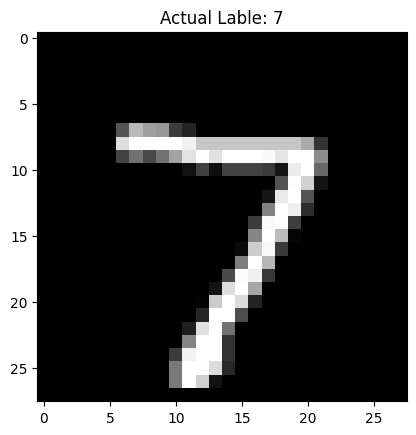

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist
import numpy as np
import matplotlib.pyplot as plt

(X_train,y_train),(X_test,y_test)=keras.datasets.mnist.load_data()

X_train = X_train.reshape(-1,28,28,1)/255.0
X_test = X_test.reshape(-1,28,28,1)/255.0

model = keras.Sequential([
    layers.Conv2D(32,(3,3),activation="relu", input_shape=(28,28,1)),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64,(3,3),activation="relu"),
    layers.MaxPooling2D((2,2)),

    layers.Flatten(),

    layers.Dense(128,activation="relu"),
    layers.Dense(10,activation="softmax")

])

model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])
model.fit(X_train,y_train,epochs=5,validation_data=(X_test,y_test))

loss,acc=model.evaluate(X_test,y_test)

print("Loss:",loss)
print("Accuracy:",acc)

plt.imshow(X_test[0].reshape(28,28),cmap='gray')
plt.title("Actual Lable: "+str(y_test[0]))
plt.show()

pred=model.predict(X_test)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
--- Model 1: Original architecture (kernel size 5x5) ---


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 13s 4ms/step - accuracy: 0.9626 - loss: 0.1223 - val_accuracy: 0.9875 - val_loss: 0.0380
Epoch 2/5
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9875 - loss: 0.0402 - val_accuracy: 0.9875 - val_loss: 0.0379
Epoch 3/5
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9913 - loss: 0.0270 - val_accuracy: 0.9892 - val_loss: 0.0331
Epoch 4/5
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9935 - loss: 0.0200 - val_accuracy: 0.9909 - val_loss: 0.0298
Epoch 5/5
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9952 - loss: 0.0155 - val_accuracy: 0.9919 - val_loss: 0.0317
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9919 - loss: 0.0317
Model 1 - Test Accuracy: 0.9919000267982483
Model 1 - Loss: 0.03172501549124718

--- Model 2: Using Average Pooling ---
Epoch 1/5
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.9567 - loss: 0.1420 - val_accuracy: 0.9860 - val_loss: 0.0496
Epoch 2/5
2000/2000 ━━━━━━━━━

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_separable_conv.py:104: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(


Epoch 1/5
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - accuracy: 0.9404 - loss: 0.1997 - val_accuracy: 0.9759 - val_loss: 0.0732
Epoch 2/5
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9798 - loss: 0.0664 - val_accuracy: 0.9837 - val_loss: 0.0497
Epoch 3/5
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9848 - loss: 0.0480 - val_accuracy: 0.9819 - val_loss: 0.0583
Epoch 4/5
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9876 - loss: 0.0379 - val_accuracy: 0.9809 - val_loss: 0.0565
Epoch 5/5
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9901 - loss: 0.0303 - val_accuracy: 0.9870 - val_loss: 0.0401
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9870 - loss: 0.0401
Model 3 - Test Accuracy: 0.9869999885559082
Model 3 - Loss: 0.040149323642253876

--- Model 4: Using Strides=2 ---
Epoch 1/5
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.9417 - loss: 0.1897 - val_accuracy: 0.9646 - val_loss: 0.1015
Epoch 2/5
2000/2000 ━━━━━━━━━━━━━━

/tmp/ipykernel_12148/3849343059.py:106: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.lineplot(x=model_names, y=accuracies, marker='o', markersize=8, palette='viridis')


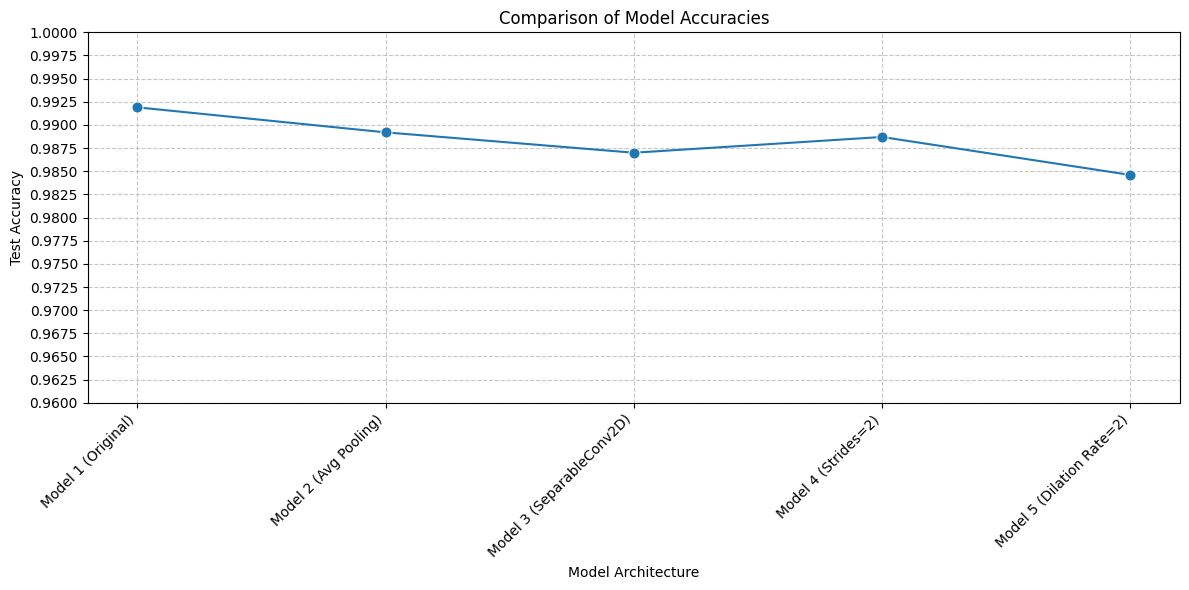

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

(x_train,y_train),(x_test,y_test)=keras.datasets.mnist.load_data()

x_train = x_train.reshape(-1,28,28,1) / 255.0
x_test = x_test.reshape(-1,28,28,1) / 255.0
y_train=keras.utils.to_categorical(y_train,num_classes=10)
y_test=keras.utils.to_categorical(y_test,num_classes=10)


print("--- Model 1: Original architecture (kernel size 5x5) ---")
model1 = keras.Sequential([
    layers.Conv2D(32,(5,5),activation='relu',input_shape=(28,28,1)),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64,(5,5),activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(128,activation='relu'),
    layers.Dense(10,activation='softmax')
])
model1.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])
model1.fit(x_train,y_train,epochs=5,batch_size=30,validation_data=(x_test,y_test))
loss1,acc1=model1.evaluate(x_test,y_test)
print(f"Model 1 - Test Accuracy: {acc1}")
print(f"Model 1 - Loss: {loss1}")

print("\n--- Model 2: Using Average Pooling ---")
model2 = keras.Sequential([
    layers.Conv2D(32,(5,5),activation='relu',input_shape=(28,28,1)),
    layers.AveragePooling2D((2,2)),
    layers.Conv2D(64,(5,5),activation='relu'),
    layers.AveragePooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(128,activation='relu'),
    layers.Dense(10,activation='softmax')
])
model2.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])
model2.fit(x_train,y_train,epochs=5,batch_size=30,validation_data=(x_test,y_test))
loss2,acc2=model2.evaluate(x_test,y_test)
print(f"Model 2 - Test Accuracy: {acc2}")
print(f"Model 2 - Loss: {loss2}")

print("\n--- Model 3: Using SeparableConv2D ---")
model3 = keras.Sequential([
    layers.SeparableConv2D(32,(5,5),activation='relu',input_shape=(28,28,1)),
    layers.MaxPooling2D((2,2)),
    layers.SeparableConv2D(64,(5,5),activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(128,activation='relu'),
    layers.Dense(10,activation='softmax')
])
model3.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])
model3.fit(x_train,y_train,epochs=5,batch_size=30,validation_data=(x_test,y_test))
loss3,acc3=model3.evaluate(x_test,y_test)
print(f"Model 3 - Test Accuracy: {acc3}")
print(f"Model 3 - Loss: {loss3}")

print("\n--- Model 4: Using Strides=2 ---")
model4 = keras.Sequential([
    layers.Conv2D(32,(5,5),strides=2,activation='relu',input_shape=(28,28,1)),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64,(5,5),strides=1,activation='relu'), # Changed strides from 2 to 1
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(128,activation='relu'),
    layers.Dense(10,activation='softmax')
])
model4.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])
model4.fit(x_train,y_train,epochs=5,batch_size=30,validation_data=(x_test,y_test))
loss4,acc4=model4.evaluate(x_test,y_test)
print(f"Model 4 - Test Accuracy: {acc4}")
print(f"Model 4 - Loss: {loss4}")

print("\n--- Model 5: Using Dilation Rate=2 ---")
model5 = keras.Sequential([
    layers.Conv2D(32,(5,5),dilation_rate=2,activation='relu',input_shape=(28,28,1)),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64,(5,5),dilation_rate=2,activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(128,activation='relu'),
    layers.Dense(10,activation='softmax')
])
model5.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])
model5.fit(x_train,y_train,epochs=5,batch_size=30,validation_data=(x_test,y_test))
loss5,acc5=model5.evaluate(x_test,y_test)
print(f"Model 5 - Test Accuracy: {acc5}")
print(f"Model 5 - Loss: {loss5}")



import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

model_names = ['Model 1 (Original)', 'Model 2 (Avg Pooling)', 'Model 3 (SeparableConv2D)', 'Model 4 (Strides=2)', 'Model 5 (Dilation Rate=2)']
accuracies = [acc1, acc2, acc3, acc4, acc5]

plt.figure(figsize=(12, 6))
sns.lineplot(x=model_names, y=accuracies, marker='o', markersize=8, palette='viridis')
plt.title('Comparison of Model Accuracies')
plt.xlabel('Model Architecture')
plt.ylabel('Test Accuracy')
plt.yticks(np.arange(0.9600, 1.0025, 0.0025)) # Set custom y-axis ticks
plt.xticks(rotation=45, ha='right')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense
from tensorflow.keras.utils import to_categorical

text = "HELLO"

chars = sorted(list(set(text)))

char_to_index = {c: i for i, c in enumerate(chars)}
index_to_char = {i: c for i, c in enumerate(chars)}

print("Character Mapping:")
print(char_to_index)

X = []
y = []

for i in range(len(text) - 1):
    X.append(char_to_index[text[i]])
    y.append(char_to_index[text[i + 1]])

X = np.array(X)
y = np.array(y)

num_classes = len(chars)

X = to_categorical(X, num_classes)
y = to_categorical(y, num_classes)

X = X.reshape((X.shape[0], 1, X.shape[1]))

print("Input Shape:", X.shape)

model = Sequential()

model.add(
    SimpleRNN(
        units=8,
        input_shape=(1, num_classes),
        activation='tanh'
    )
)

model.add(
    Dense(
        num_classes,
        activation='softmax'
    )
)

model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.fit(
    X,
    y,
    epochs=200,
    verbose=1
)

def predict_next_char(char):

    x = char_to_index[char]

    x = to_categorical(x, num_classes)

    x = x.reshape((1, 1, num_classes))

    prediction = model.predict(x, verbose=0)

    index = np.argmax(prediction)

    return index_to_char[index]

print("\nTesting Prediction:")

test_char = "H"

next_char = predict_next_char(test_char)

print("Input:", test_char)
print("Predicted Next Character:", next_char)

print("\nGenerated Text:")
char = "H"
generated_text = char
for i in range(4):
    next_char = predict_next_char(char)
    generated_text += next_char
    char = next_char
print(generated_text)


Character Mapping:
{'E': 0, 'H': 1, 'L': 2, 'O': 3}
Input Shape: (4, 1, 4)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.5000 - loss: 1.3487
Epoch 2/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step - accuracy: 0.5000 - loss: 1.3446
Epoch 3/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step - accuracy: 0.5000 - loss: 1.3405
Epoch 4/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 292ms/step - accuracy: 0.5000 - loss: 1.3364
Epoch 5/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 191ms/step - accuracy: 0.5000 - loss: 1.3323
Epoch 6/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step - accuracy: 0.5000 - loss: 1.3283
Epoch 7/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step - accuracy: 0.5000 - loss: 1.3242
Epoch 8/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step - accuracy: 0.5000 - loss: 1.3202
Epoch 9/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.5000 - loss: 1.3163
Epoch 10/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.5000 - loss: 1.3123
Epoch 11/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.5000 - loss: 1.3084
Epoch 12/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step - accuracy: 0.50

In [ ]:
# ==========================================
# Seq2Seq Encoder-Decoder using SimpleRNN
# With Translation Testing
# ==========================================

import numpy as np
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, SimpleRNN, Dense, Embedding
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# ------------------------------------------
# Step 1: Dataset
# ------------------------------------------

# English → French word pairs
input_texts = ["hi", "bye"]
target_texts = ["salut", "merci"]

# ------------------------------------------
# Step 2: Tokenization
# ------------------------------------------

in_tok = Tokenizer(char_level=True)
out_tok = Tokenizer(char_level=True)

in_tok.fit_on_texts(input_texts)
out_tok.fit_on_texts(target_texts)

# Convert to sequences
encoder_seq = in_tok.texts_to_sequences(input_texts)
decoder_seq = out_tok.texts_to_sequences(target_texts)

# Padding
max_enc_len = max(len(seq) for seq in encoder_seq)
max_dec_len = max(len(seq) for seq in decoder_seq)

encoder_input = pad_sequences(
    encoder_seq,
    maxlen=max_enc_len,
    padding='post'
)

decoder_input = pad_sequences(
    decoder_seq,
    maxlen=max_dec_len,
    padding='post'
)

# Decoder target (same as input for simple demo)
decoder_target = np.expand_dims(decoder_input, -1)

# Vocabulary sizes
enc_vocab = len(in_tok.word_index) + 1
dec_vocab = len(out_tok.word_index) + 1

latent_dim = 16

# ------------------------------------------
# Step 3: Encoder
# ------------------------------------------

encoder_inputs = Input(shape=(None,))

enc_embed = Embedding(
    enc_vocab,
    latent_dim
)(encoder_inputs)

encoder_rnn = SimpleRNN(
    latent_dim,
    return_state=True
)

encoder_outputs, state = encoder_rnn(enc_embed)

# ------------------------------------------
# Step 4: Decoder
# ------------------------------------------

decoder_inputs = Input(shape=(None,))

dec_embed = Embedding(
    dec_vocab,
    latent_dim
)(decoder_inputs)

decoder_rnn = SimpleRNN(
    latent_dim,
    return_sequences=True,
    return_state=True
)

decoder_outputs, _ = decoder_rnn(
    dec_embed,
    initial_state=state
)

decoder_dense = Dense(
    dec_vocab,
    activation='softmax'
)

decoder_outputs = decoder_dense(decoder_outputs)

# ------------------------------------------
# Step 5: Create Model
# ------------------------------------------

model = Model(
    [encoder_inputs, decoder_inputs],
    decoder_outputs
)

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy'
)

model.summary()

# ------------------------------------------
# Step 6: Train Model
# ------------------------------------------

model.fit(
    [encoder_input, decoder_input],
    decoder_target,
    epochs=200,
    verbose=1
)

print("\nModel Training Completed!")

# ------------------------------------------
# Step 7: Translation Function
# ------------------------------------------

# Reverse dictionary
rev_out_index = {
    v: k for k, v in out_tok.word_index.items()
}

def translate_word(word):

    seq = in_tok.texts_to_sequences([word])

    seq = pad_sequences(
        seq,
        maxlen=max_enc_len,
        padding='post'
    )

    # Empty decoder input
    dec_input = np.zeros(
        (1, max_dec_len)
    )

    pred = model.predict(
        [seq, dec_input],
        verbose=0
    )

    pred_indices = np.argmax(
        pred[0],
        axis=1
    )

    translated = ""

    for idx in pred_indices:
        if idx in rev_out_index:
            translated += rev_out_index[idx]

    return translated


# ------------------------------------------
# Step 8: Test Translation
# ------------------------------------------

while True:

    word = input("\nEnter English word (or 'exit'): ")

    if word == "exit":
        break

    result = translate_word(word)

    print("Translated word:", result)

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_6       │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_7       │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, None, 16)  │         96 │ input_layer_6[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, None, 16)  │        176 │ input_layer_7[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ simple_rnn          │ [(None, 16),      │        528 │ embedding[0][0]   │
│ (SimpleRNN)         │ (None, 16)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ simple_rnn_1        │ [(None, None,     │        528 │ embedding_1[0][0… │
│ (SimpleRNN)         │ 16), (None, 16)]  │            │ simple_rnn[0][1]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, None, 11)  │        187 │ simple_rnn_1[0][… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,515 (5.92 KB)

 Trainable params: 1,515 (5.92 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step - loss: 2.3971
Epoch 2/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 2.3789
Epoch 3/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 2.3608
Epoch 4/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 2.3427
Epoch 5/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 2.3247
Epoch 6/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - loss: 2.3065
Epoch 7/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 2.2883
Epoch 8/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 2.2698
Epoch 9/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 2.2511
Epoch 10/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 2.2322
Epoch 11/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 2.2130
Epoch 12/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 2.1934
Epoch 13/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 2.1735
Epoch 14/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 2.1532
Epoch 15/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 2.1326
Epoch 16/200
1/1 ━━━━

Dataset loaded - 144 monthly records
   Passengers
0         112
1         118
2         132
3         129
4         121
Train set size: 107
Test set size: 27
LSTM Model Trained
GRU Model Trained
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step


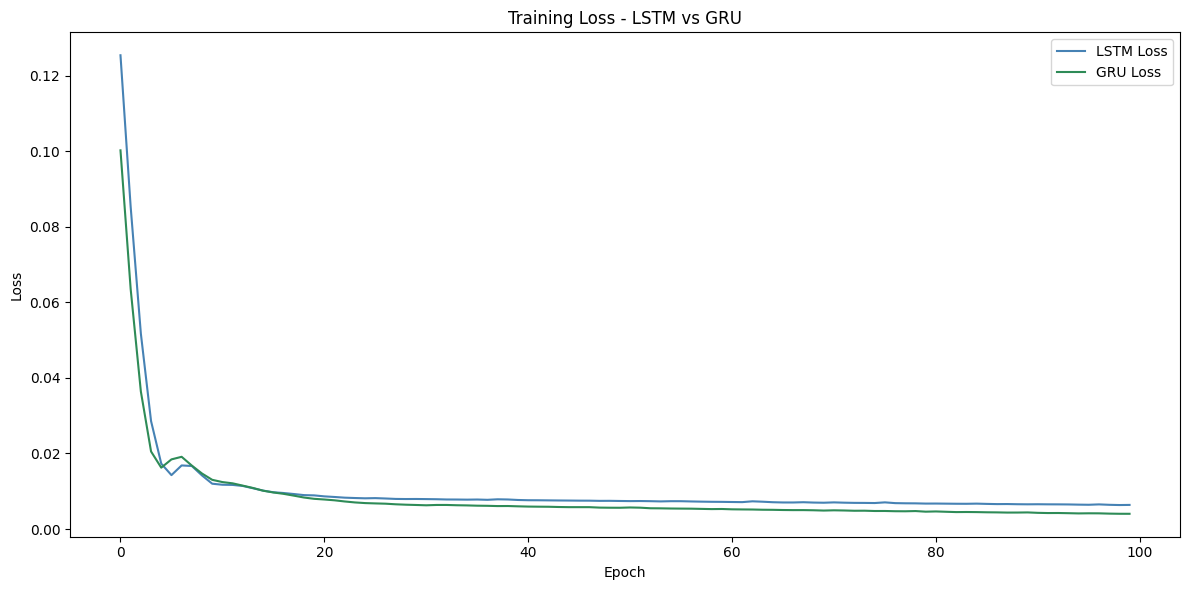

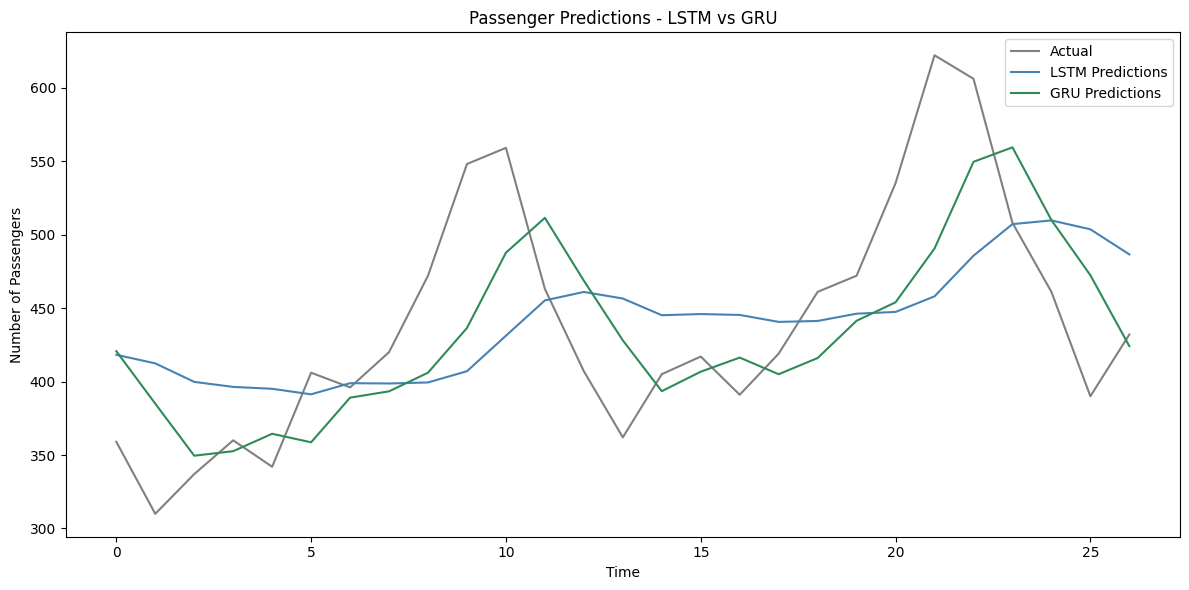


Month | Actual | LSTM | GRU
                                          
1     |    359 |  418 | 421
2     |    310 |  412 | 385
3     |    337 |  400 | 350
4     |    360 |  396 | 353
5     |    342 |  395 | 364
6     |    406 |  391 | 359
7     |    396 |  399 | 389
8     |    420 |  399 | 393
9     |    472 |  399 | 406
10    |    548 |  407 | 436
11    |    559 |  431 | 488
12    |    463 |  455 | 511
13    |    407 |  461 | 469
14    |    362 |  456 | 428
15    |    405 |  445 | 393
16    |    417 |  446 | 407
17    |    391 |  445 | 416
18    |    419 |  441 | 405
19    |    461 |  441 | 416
20    |    472 |  446 | 441
21    |    535 |  447 | 454
22    |    622 |  458 | 491
23    |    606 |  486 | 549
24    |    508 |  507 | 559
25    |    461 |  510 | 510
26    |    390 |  504 | 472
27    |    432 |  487 | 424

***********************************************
Model            MSE     Parameters
------------------------------------------
LSTM         5568.98           4385
GRU     

In [ ]:
import matplotlib.pyplot as plt
import urllib.request
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, GRU, Dense, Input
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
import pandas as pd
import numpy as np

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
urllib.request.urlretrieve(url, "airline.csv")
df = pd.read_csv("airline.csv", usecols=[1]) # Select only the 'Passengers' column
data = df.values.astype(float)
print(f"Dataset loaded - {len(data)} monthly records")
print(df.head())

scaler = MinMaxScaler(feature_range=(0,1))
data_scaled = scaler.fit_transform(data)

def create_sequence(data, seq_len):
  X, y = [], []
  for i in range(len(data) - seq_len):
    X.append(data[i:i+seq_len])
    y.append(data[i+seq_len])
  return np.array(X), np.array(y)

X, y = create_sequence(data_scaled, seq_len=10)
split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]
print(f"Train set size: {len(X_train)}")
print(f"Test set size: {len(X_test)}")

lstm_model = Sequential([Input(shape=(10, 1)), LSTM(32), Dense(1)])
lstm_model.compile(optimizer='adam', loss='mse')
lstm_history = lstm_model.fit(X_train, y_train, epochs=100, batch_size=32, verbose=0)
print("LSTM Model Trained")

GRU_model = Sequential([Input(shape=(10, 1)), GRU(32), Dense(1)])
GRU_model.compile(optimizer='adam', loss='mse')
GRU_history = GRU_model.fit(X_train, y_train, epochs=100, batch_size=32, verbose=0)
print("GRU Model Trained")

lstm_predictions = lstm_model.predict(X_test)
gru_predictions = GRU_model.predict(X_test)

plt.figure(figsize=(12,6))
plt.plot(lstm_history.history['loss'], label='LSTM Loss', color='steelblue')
plt.plot(GRU_history.history['loss'], label='GRU Loss', color='seagreen')
plt.title('Training Loss - LSTM vs GRU')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

real_actual = scaler.inverse_transform(y_test)
lstm_actual_predictions = scaler.inverse_transform(lstm_predictions)
gru_actual_predictions = scaler.inverse_transform(gru_predictions)

plt.figure(figsize=(12,6))
plt.plot(real_actual, label= 'Actual', color='gray', linewidth=1.5)
plt.plot(lstm_actual_predictions, label='LSTM Predictions', color='steelblue', linewidth=1.5)
plt.plot(gru_actual_predictions, label='GRU Predictions', color='seagreen', linewidth=1.5)
plt.title('Passenger Predictions - LSTM vs GRU')
plt.xlabel('Time')
plt.ylabel('Number of Passengers')
plt.legend()
plt.tight_layout()
plt.show()

print("\nMonth | Actual | LSTM | GRU")
print(" " * 42)
for i in range(len(real_actual)):
  print(f"{i+1:<5} | {real_actual[i][0]:>6.0f} | {lstm_actual_predictions[i][0]:>4.0f} | {gru_actual_predictions[i][0]:>3.0f}")

lstm_mse = mean_squared_error(real_actual, lstm_actual_predictions)
gru_mse = mean_squared_error(real_actual, gru_actual_predictions)

print("\n" + "*" * 47)
print(f"{'Model':<10}{'MSE':>10}{'Parameters':>15}")
print("-" * 42)
print(f"{'LSTM':<10}{lstm_mse:>10.2f}{lstm_model.count_params():>15}")
print(f"{'GRU':<10}{gru_mse:>10.2f}{GRU_model.count_params():>15}")
print("*" * 47 + "\n")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.2443
Epoch 2/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1417
Epoch 3/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1176
Epoch 4/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1038
Epoch 5/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0949
Epoch 1/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.1459
Epoch 2/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1242
Epoch 3/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1207
Epoch 4/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1187
Epoch 5/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1173
Epoch 1/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - loss: 237.1682
Epoch 2/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 182.8442
Epoch 3/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 173.4989
Epoch 4/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 167.9287
Epoch 5/5
235/2

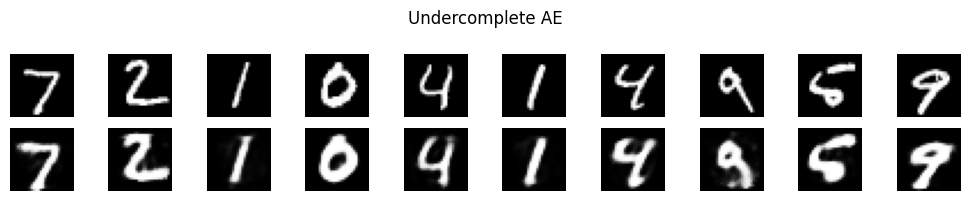

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


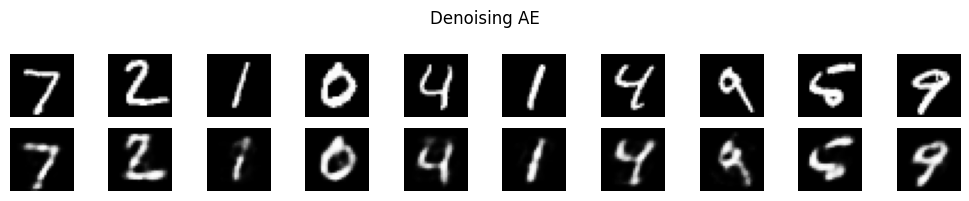

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step


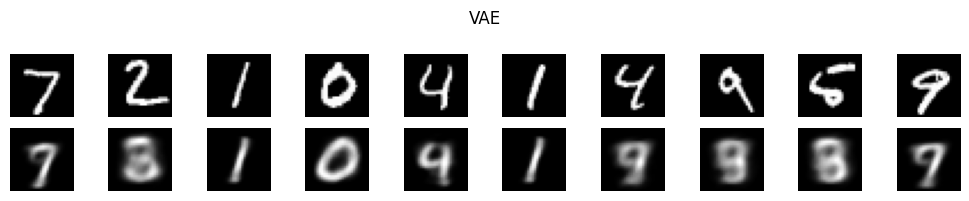

In [ ]:
import numpy as np, tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

# 📥 Load & preprocess MNIST
(x_train, _), (x_test, _) = tf.keras.datasets.mnist.load_data()
x_train, x_test = x_train.astype("float32") / 255., x_test.astype("float32") / 255.
x_train, x_test = x_train[..., np.newaxis], x_test[..., np.newaxis]

# 🧼 Add noise for Denoising Autoencoder
def add_noise(x): return np.clip(x + 0.5 * np.random.randn(*x.shape), 0., 1.)
x_train_noisy, x_test_noisy = add_noise(x_train), add_noise(x_test)

# 🏗️ Common encoder and decoder layers
enc = models.Sequential([layers.Input((28, 28, 1)), layers.Flatten(), layers.Dense(64, activation='relu')])
dec = models.Sequential([layers.Input((64,)), layers.Dense(784, activation='sigmoid'), layers.Reshape((28, 28, 1))])

# 1️⃣ Undercomplete Autoencoder
ucae = models.Sequential([enc, dec])
ucae.compile(optimizer='adam', loss='binary_crossentropy')
ucae.fit(x_train, x_train, epochs=5, batch_size=256, verbose=1)

# 2️⃣ Denoising Autoencoder
dnae = models.Sequential([enc, dec])
dnae.compile(optimizer='adam', loss='binary_crossentropy')
dnae.fit(x_train_noisy, x_train, epochs=5, batch_size=256, verbose=1)

# 3️⃣ Variational Autoencoder (fixed)
class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        epsilon = tf.random.normal(shape=tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

# Encoder for VAE
inputs = layers.Input(shape=(28, 28, 1))
x = layers.Flatten()(inputs)
x = layers.Dense(128, activation="relu")(x)
z_mean = layers.Dense(2, name="z_mean")(x)
z_log_var = layers.Dense(2, name="z_log_var")(x)
z = Sampling()([z_mean, z_log_var])
encoder = tf.keras.Model(inputs, [z_mean, z_log_var, z], name="encoder")

# Decoder for VAE
latent_inputs = layers.Input(shape=(2,))
x = layers.Dense(128, activation="relu")(latent_inputs)
x = layers.Dense(784, activation="sigmoid")(x)
outputs = layers.Reshape((28, 28, 1))(x)
decoder = tf.keras.Model(latent_inputs, outputs, name="decoder")

# Custom VAE class
class VAE(tf.keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder

    def call(self, inputs):
        z_mean, z_log_var, z = self.encoder(inputs)
        reconstruction = self.decoder(z)
        # Compute loss inside the model (safe with symbolic tensors)
        recon_loss = tf.reduce_mean(
            tf.keras.losses.binary_crossentropy(inputs, reconstruction)
        ) * 784
        kl_loss = -0.5 * tf.reduce_mean(
            1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var)
        )
        self.add_loss(recon_loss + kl_loss)
        return reconstruction

# Compile and train VAE
vae = VAE(encoder, decoder)
vae.compile(optimizer="adam")
vae.fit(x_train, x_train, epochs=5, batch_size=256, verbose=1)

# 🔍 Plotting function
def show_imgs(orig, recon, title):
    plt.figure(figsize=(10, 2))
    n = min(10, len(orig))
    for i in range(n):
        plt.subplot(2, n, i+1)
        img = orig[i].squeeze() if orig[i].ndim == 3 else orig[i]
        plt.imshow(img, cmap='gray')
        plt.axis('off')

        plt.subplot(2, n, i + n + 1)
        img = recon[i].squeeze() if recon[i].ndim == 3 else recon[i]
        plt.imshow(img, cmap='gray')
        plt.axis('off')
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

# 📸 Visualize reconstructions
show_imgs(x_test, ucae.predict(x_test), "Undercomplete AE")
show_imgs(x_test, dnae.predict(x_test_noisy), "Denoising AE")
show_imgs(x_test, vae.predict(x_test), "VAE")